# Brunelli — final complete thesis workflow (SLA-based crop-damage interface)

This notebook is the **complete Brunelli workflow prepared for supervisor review**. It contains:

- loading and auditing the prepared hourly Brunelli dataset;
- the closed Egg → Larva → Pupa → Adult → Egg model;
- TOMGRO/PyCrop crop growth and native biomass states;
- temperature-dependent Egg, Pupa and Larva development;
- Differential Evolution code for initial pest-state estimation;
- the retained DE solution used for routine reproducible reruns;
- focused refinement of existing Egg/larval-capacity parameters;
- final OBS-vs-SIM Egg, Larva and Adult plots;
- a no-pest counterfactual;
- LAI and fruit-biomass impact;
- CSV exports and final consistency checks.

## Brunelli crop-damage interface

The crop-side conversion used in the final Brunelli run is

\[
B_L=\frac{LAI}{SLA},\qquad
p_d(B_L)=\alpha\frac{B_L}{B_L+\delta},\qquad
D_{LAI}=SLA\,p_d(B_L)L,
\]

with `SLA = 0.018`.

The pest-resource side remains the retained Coppola/Brunelli formulation (`F_resource = LAI/Omega`). The SLA conversion is used only for translating larval leaf consumption into LAI loss on the crop side.

No normalisation, smoothing, fitted observation multiplier `q`, immigration term, or post-hoc time shift is used. Adult trap observations are compared with interval-integrated simulated Adult exposure.


## 1. Setup and PyCrop discovery


In [1]:
from __future__ import annotations

import math
import os
import sys
import zipfile
from decimal import Decimal
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from scipy.optimize import differential_evolution

try:
    from IPython.display import display
except Exception:
    def display(x):
        print(x)

HERE = Path.cwd().resolve()
OUTPUT_DIR = HERE / "outputs_brunelli_common_SLA"
OUTPUT_DIR.mkdir(exist_ok=True)


def D(x):
    return Decimal(str(x))


def find_or_extract_pycrop() -> Path:
    candidates = []
    env_root = os.environ.get("PYCROP_ROOT")
    if env_root:
        candidates.append(Path(env_root).expanduser())
    candidates.extend([
        HERE,
        HERE / "PyCrop_restrict",
        HERE / "_pycrop_runtime" / "PyCrop_restrict",
        HERE.parent,
    ])
    for candidate in candidates:
        try:
            candidate = candidate.resolve()
        except OSError:
            continue
        if (candidate / "PyCrop").is_dir():
            return candidate

    zip_candidates = [
        HERE / "PyCrop_restrict (2).zip",
        HERE / "PyCrop_restrict.zip",
        HERE.parent / "PyCrop_restrict (2).zip",
        Path("/mnt/data/PyCrop_restrict (2).zip"),
    ]
    zpath = next((p for p in zip_candidates if p.exists()), None)
    if zpath is None:
        raise FileNotFoundError("PyCrop_restrict (2).zip was not found.")

    runtime = HERE / "_pycrop_runtime"
    runtime.mkdir(exist_ok=True)
    with zipfile.ZipFile(zpath, "r") as z:
        z.extractall(runtime)
    roots = [runtime, *[p for p in runtime.rglob("*") if p.is_dir()]]
    root = next((p for p in roots if (p / "PyCrop").is_dir()), None)
    if root is None:
        raise FileNotFoundError("No extracted folder containing PyCrop/ was found.")
    return root

PYCROP_ROOT = find_or_extract_pycrop()
if str(PYCROP_ROOT) not in sys.path:
    sys.path.insert(0, str(PYCROP_ROOT))

from PyCrop.Implementations.Environment.SimpleEnvironmentModule import WM2TOPPFD
from PyCrop.Implementations.TOMGRO.TOMGROBiomassModule import TOMGROBiomassModule, BIOMASS_DEFAULT_PARAMS

print("Notebook root:", HERE)
print("PyCrop root:", PYCROP_ROOT)
print("Output dir:", OUTPUT_DIR)


Notebook root: /mnt/data/milan_compare_update_v2
PyCrop root: /mnt/data/milan_compare_update_v2/_pycrop_runtime/PyCrop_restrict
Output dir: /mnt/data/milan_compare_update_v2/outputs_brunelli_common_SLA


## 2. Brunelli data and observation mapping


In [2]:
DATASET_PATH = HERE / "brunelli_final_dataset.csv"
if not DATASET_PATH.exists():
    raise FileNotFoundError(DATASET_PATH)

raw = pd.read_csv(DATASET_PATH, parse_dates=["datetime"]).sort_values("datetime").reset_index(drop=True)
required = ["datetime", "Temperature", "RADSOL", "Eggs", "Larvae", "Adults_Brunelli"]
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

START = raw["datetime"].min()
raw["Day_float"] = (raw["datetime"] - START).dt.total_seconds() / 86400.0
raw["Day"] = np.floor(raw["Day_float"]).astype(int)

EGG_LARVA_DAYS = np.array([0, 6, 13, 20, 27, 34, 41, 48, 55, 62, 69], dtype=int)
ADULT_DAYS = np.array([0, 7, 14, 21, 28, 36, 42, 48, 55, 62, 69], dtype=int)

daily_first = raw.groupby("Day", as_index=False).agg(
    Eggs=("Eggs", "first"),
    Larvae=("Larvae", "first"),
    Adults=("Adults_Brunelli", "first"),
)

egg_obs = daily_first.set_index("Day").loc[EGG_LARVA_DAYS, "Eggs"].to_numpy(float)
larva_obs = daily_first.set_index("Day").loc[EGG_LARVA_DAYS, "Larvae"].to_numpy(float)
adult_obs = daily_first.set_index("Day").loc[ADULT_DAYS, "Adults"].to_numpy(float)

N_HOURS = 70 * 24
raw = raw.iloc[:N_HOURS].copy()
hourly_temperature = raw["Temperature"].to_numpy(float)
hourly_radiation = raw["RADSOL"].to_numpy(float)

daily_temperature = (
    raw.groupby("Day")["Temperature"].mean().reindex(range(70)).interpolate().ffill().bfill().to_numpy(float)
)
daytime_temperature = np.array([
    raw.iloc[d*24 + 6 : d*24 + 19]["Temperature"].mean() for d in range(70)
], dtype=float)

hourly_ppfd = hourly_radiation * float(WM2TOPPFD)
hourly_co2 = raw["CO2"].astype(float).to_numpy() if "CO2" in raw.columns else np.full(N_HOURS, 400.0)

print("Dataset start:", START)
display(pd.DataFrame({"Day": EGG_LARVA_DAYS, "Egg_obs": egg_obs, "Larva_obs": larva_obs}))


Dataset start: 2025-07-16 00:00:00


,Day,Egg_obs,Larva_obs
0,0,0.03,0.00
1,6,0.02,0.02
2,13,0.06,0.11
3,20,0.02,0.10
4,27,0.01,0.20
5,34,0.19,0.12
6,41,0.37,0.30
7,48,0.31,0.18
8,55,0.34,0.07
9,62,0.16,0.19


## 3. Model parameters and agreed Brunelli baseline


In [3]:
MILAN = {
    "mu_E": 0.24,
    "mu_L": 0.22,
    "mu_P": 0.04,
    "mu_A": 0.27,
    "zeta_A": 10.28,
    "a2": 51.948,   # direct Egg-duration parameter; no separate multiplier
    "b2": 0.10,
    "a3": 73.78,
    "b3": 0.09,
    "fertility_a": 290.58,
    "fertility_b": 1.57,
    "fertility_c": 20.64,
    "T_pest_min": 4.90,
    "T_pest_max": 32.7,
    "alpha": 0.00065,
    "delta": 35.0,
    "epsilon_max": 0.55,
    "chi": 0.004,
    "Omega": 1.0 / 35.0,
    "nu": 0.000755,
}

CROP_IC = {"N0": 22.0, "LAI0": 0.5, "W0": 60.0, "Wf0": 20.0, "Wm0": 0.0}

# SLA-based crop-damage interface used in the final Brunelli run.
COMMON_DAMAGE = {"SLA": 0.018}

# Retained initial-state solution from the DE calibration stage.
# It is used by default so routine reruns do not repeat the slow global search.
FROZEN_IC = {"E0": 531.0, "L0": 438.0, "P0": 349.0, "A0": 0.0}

# Rate values held fixed during the initial-state DE search.
# The earlier calibration implementation used a2=57.72 with an Egg-duration
# multiplier of 0.90; in the final no-multiplier formulation this is exactly
# represented by direct a2 = 57.72 * 0.90 = 51.948.
# nu=0.0005 belongs to the IC-search stage; nu is revisited only after the ICs
# are frozen, in the focused rate-parameter refinement below.
DE_IC_RATE_PARAMS = {
    "a2": 51.948,
    "b2": 0.10,
    "mu_E": 0.24,
    "nu": 0.0005,
}

BASELINE_PARAMS = {
    "a2": 51.948,
    "b2": 0.10,
    "mu_E": 0.24,
    "nu": 0.000755,
}

display(pd.DataFrame([
    {"Parameter": k, "Value": v} for k, v in BASELINE_PARAMS.items()
]))


,Parameter,Value
0,a2,51.948000
1,b2,0.100000
2,mu_E,0.240000
3,nu,0.000755


### Resource and crop-damage conversions used in the coupled model

Two interfaces are kept conceptually distinct.

1. **Pest resource availability** retains the Coppola-derived conversion used during Brunelli pest calibration:

\[F_{resource}=LAI/\Omega.\]

2. **Crop damage** uses the SLA-based leaf-biomass conversion adopted for the final Brunelli run:

\[B_L=LAI/SLA,\qquad D_{LAI}=SLA\,\alpha\frac{B_L}{B_L+\delta}L.\]

The first relation belongs to the pest-resource dynamics; the second determines how larval consumption is expressed as crop leaf-area loss. Keeping the two roles explicit makes the coupling traceable without changing the calibrated pest-resource definition.


## 4. TOMGRO node and LAI-growth driver


In [4]:
def delta_nodes_from_temperature(T):
    return max(0.0, 0.036 * (T - 9.0))

TOMGRO_LAI = {"N0": CROP_IC["N0"], "LAI0": CROP_IC["LAI0"], "a": 0.001, "b": 250000.0, "c": 1.435, "d": 3.6}

nodes = TOMGRO_LAI["N0"]
tomgro_rows = []
for day, T in enumerate(daily_temperature):
    DN = delta_nodes_from_temperature(T)
    nodes += DN
    a, b, c, d = TOMGRO_LAI["a"], TOMGRO_LAI["b"], TOMGRO_LAI["c"], TOMGRO_LAI["d"]
    DLAI = (b * d * (c - a) * nodes ** (d - 1) / (b + nodes ** d) ** 2) * DN
    tomgro_rows.append((day, T, nodes, DN, DLAI))

tomgro_driver = pd.DataFrame(tomgro_rows, columns=["Day", "Temperature", "Nodes", "Delta_Nodes", "TOMGRO_DLAI"])
display(tomgro_driver.head())


,Day,Temperature,Nodes,Delta_Nodes,TOMGRO_DLAI
0,0,26.816030,22.641377,0.641377,0.026043
1,1,26.048606,23.255127,0.613750,0.025506
2,2,26.458101,23.883619,0.628492,0.026638
3,3,26.325671,24.507343,0.623724,0.026852
4,4,26.841746,25.149646,0.642303,0.027989


## 5. Temperature-dependent pest functions


In [5]:
def total_fertility(T, p):
    T = np.asarray(T, dtype=float)
    out = np.zeros_like(T)
    valid = (T > p["T_pest_min"]) & (T < p["T_pest_max"])
    out[valid] = (
        p["fertility_a"]
        * (T[valid] - p["T_pest_min"]) ** p["fertility_b"]
        * (p["T_pest_max"] - T[valid])
        / ((p["fertility_c"] - p["T_pest_min"]) ** p["fertility_b"] * (p["T_pest_max"] - p["T_pest_min"]))
    )
    return out


def phi_temperature(T, p):
    return total_fertility(T, p) / (2.0 * p["zeta_A"])


def zeta_egg(T, p):
    return p["a2"] * np.exp(-p["b2"] * np.asarray(T, dtype=float))


def zeta_pupa(T, p):
    return p["a3"] * np.exp(-p["b3"] * np.asarray(T, dtype=float))

LARVA_SD6 = {"P": 0.1125, "T0_K": 298.8563, "HA": 9683.435, "HH": 2555621.0, "TH_K": 310.4786, "R": 1.987}


def larval_development_rate_paper(T_c):
    q = LARVA_SD6
    T_k = float(T_c) + 273.15
    numerator = q["P"] * (T_k / q["T0_K"]) * math.exp((q["HA"] / q["R"]) * (1.0 / q["T0_K"] - 1.0 / T_k))
    high_inactivation = math.exp((q["HH"] / q["R"]) * (1.0 / q["TH_K"] - 1.0 / T_k))
    return max(float(numerator / (1.0 + high_inactivation)), 1e-12)

R25 = larval_development_rate_paper(25.0)
print("Sharpe-DeMichele rate at 25 C:", R25)


Sharpe-DeMichele rate at 25 C: 0.10798120500092873


## 6. Coupled hourly RK4 engine — no additional recruitment correction


In [6]:
class BrunelliCoupledEngine:
    def __init__(self, params=None, pest_ic=None, include_biomass=True, pest_on=True):
        self.p = dict(MILAN)
        if params:
            for key, value in params.items():
                if key not in self.p:
                    raise KeyError(f"Unknown model parameter: {key}")
                self.p[key] = float(value)
        self.pest_ic = dict(PEST_IC if pest_ic is None else pest_ic)
        self.include_biomass = bool(include_biomass)
        self.pest_on = bool(pest_on)

    def make_biomass_module(self):
        params = dict(BIOMASS_DEFAULT_PARAMS)
        params["W_0"] = D(CROP_IC["W0"])
        params["W_f0"] = D(CROP_IC["Wf0"])
        params["W_m0"] = D(CROP_IC["Wm0"])
        return TOMGROBiomassModule(params=params)

    def run(self):
        if self.pest_on:
            E, L, P, A = (float(self.pest_ic[k]) for k in ["E0", "L0", "P0", "A0"])
        else:
            E = L = P = A = 0.0
        LAI = float(CROP_IC["LAI0"])
        dt = 1.0 / 24.0
        cumulative_adult_exposure = 0.0
        rows = []
        biomass = self.make_biomass_module() if self.include_biomass else None

        for hour_index in range(N_HOURS):
            day = hour_index // 24
            hour_of_day = hour_index % 24
            T = float(hourly_temperature[hour_index])
            nodes = float(tomgro_driver.loc[day, "Nodes"])
            DN = float(tomgro_driver.loc[day, "Delta_Nodes"])
            DLAI = float(tomgro_driver.loc[day, "TOMGRO_DLAI"])

            if biomass is not None:
                W = float(biomass.state_variables["W"])
                Wf = float(biomass.state_variables["W_f"])
                Wm = float(biomass.state_variables["W_m"])
            else:
                W = Wf = Wm = np.nan

            def flows(e, l, pu, aa, lai):
                e, l, pu, aa, lai = [max(float(x), 0.0) for x in [e, l, pu, aa, lai]]

                F_local = lai / self.p["Omega"] if self.p["Omega"] > 0 else 0.0
                pF_local = self.p["alpha"] * F_local / (F_local + self.p["delta"]) if F_local > 0 else 0.0
                zL_coppola = self.p["chi"] / (self.p["epsilon_max"] * pF_local) if self.p["epsilon_max"] * pF_local > 0 else 1e12
                zL_local = zL_coppola * (R25 / larval_development_rate_paper(T))

                zE = float(zeta_egg([T], self.p)[0])
                zP = float(zeta_pupa([T], self.p)[0])
                phi = float(phi_temperature([T], self.p)[0])

                hatching = e / max(zE, 1e-12)
                capacity = F_local * self.p["Omega"] / self.p["nu"]
                free_spots = max(0.0, capacity - l)
                larval_inflow = min(hatching, free_spots)

                pupation = l / max(zL_local, 1e-12)
                adult_emergence = pu / max(zP, 1e-12)
                # SLA-based crop-damage interface.
                # Pest resource F_local above remains the Coppola/Brunelli resource definition.
                B_leaf = lai / COMMON_DAMAGE["SLA"] if COMMON_DAMAGE["SLA"] > 0 else 0.0
                p_damage = self.p["alpha"] * B_leaf / (B_leaf + self.p["delta"]) if B_leaf > 0 else 0.0
                leaf_consumption = p_damage * l
                damage_lai_rate = COMMON_DAMAGE["SLA"] * leaf_consumption

                rhs = np.array([
                    phi * aa - hatching - self.p["mu_E"] * e,
                    larval_inflow - pupation - self.p["mu_L"] * l,
                    pupation - adult_emergence - self.p["mu_P"] * pu,
                    adult_emergence - self.p["mu_A"] * aa,
                    DLAI - damage_lai_rate,
                ], dtype=float)

                return {
                    "rhs": rhs,
                    "zE": zE,
                    "zL": zL_local,
                    "zP": zP,
                    "phi": phi,
                    "Hatching": hatching,
                    "Larval_Inflow": larval_inflow,
                    "Pupation": pupation,
                    "Adult_Emergence": adult_emergence,
                    "Leaf_Consumption": leaf_consumption,
                    "Damage_LAI_Rate": damage_lai_rate,
                    "Capacity": capacity,
                    "F": F_local,
                }

            f0 = flows(E, L, P, A, LAI)
            rows.append({
                "Hour": hour_index,
                "Day_float": hour_index / 24.0,
                "Day": day,
                "Eggs": E,
                "Larvae": L,
                "Pupae": P,
                "Adults": A,
                "LAI": LAI,
                "Nodes": nodes,
                "Delta_Nodes": DN,
                "W": W,
                "Wf": Wf,
                "Wm": Wm,
                "Cumulative_Adult_Exposure": cumulative_adult_exposure,
                **{k: v for k, v in f0.items() if k != "rhs"},
            })

            if biomass is not None:
                biomass.step([
                    hour_of_day,
                    T,
                    float(daily_temperature[day]),
                    float(daytime_temperature[day]),
                    float(hourly_co2[hour_index]),
                    float(hourly_ppfd[hour_index]),
                    int(round(nodes)),
                    float(DN),
                    float(LAI),
                ])

            state = np.array([E, L, P, A, LAI], dtype=float)
            def rhs(x):
                return flows(*x)["rhs"]
            k1 = rhs(state)
            k2 = rhs(np.maximum(state + 0.5 * dt * k1, 0.0))
            k3 = rhs(np.maximum(state + 0.5 * dt * k2, 0.0))
            k4 = rhs(np.maximum(state + dt * k3, 0.0))
            state = np.maximum(state + dt * (k1 + 2*k2 + 2*k3 + k4) / 6.0, 0.0)
            E, L, P, A, LAI = state
            cumulative_adult_exposure += A * dt

        return pd.DataFrame(rows)


def daily_rows(sim):
    return sim.iloc[np.arange(0, len(sim), 24)].reset_index(drop=True)


def adult_interval_exposure(sim):
    cumulative = sim["Cumulative_Adult_Exposure"].to_numpy(float)
    return np.diff(cumulative[ADULT_DAYS * 24])


def direction_count(obs, pred):
    return int(np.sum(np.sign(np.diff(obs)) == np.sign(np.diff(pred))))


def stage_metrics(obs, pred):
    return {
        "Pearson_r": float(pearsonr(obs, pred)[0]) if np.std(pred) > 0 else np.nan,
        "Spearman_rho": float(spearmanr(obs, pred)[0]) if np.std(pred) > 0 else np.nan,
        "Direction_match": direction_count(obs, pred),
        "Direction_total": len(obs) - 1,
    }

print("Engine ready.")


Engine ready.


## 7. Differential Evolution estimation of the initial pest state

The full DE calibration code is included below for reproducibility. Routine executions keep `RUN_DE_IC_SEARCH=False` and load the retained integer solution `(E0,L0,P0,A0)=(531,438,349,0)` so that the notebook can be rerun quickly and deterministically. Setting the switch to `True` reruns the global IC search using the equations currently defined in this notebook, including the final Brunelli SLA-based crop-damage interface.


In [7]:
# ----- Initial-state DE calibration -----
RUN_DE_IC_SEARCH = False  # True = rerun the slow global IC search in this notebook

IC_BOUNDS = [
    (0, 800),   # E0
    (0, 800),   # L0
    (0, 600),   # P0
    (0, 40),    # A0
]


def ic_de_objective(x):
    E0, L0, P0, A0 = [float(v) for v in x]
    candidate_ic = {"E0": E0, "L0": L0, "P0": P0, "A0": A0}

    sim = BrunelliCoupledEngine(
        params=DE_IC_RATE_PARAMS,
        pest_ic=candidate_ic,
        include_biomass=False,
        pest_on=True,
    ).run()
    daily = daily_rows(sim)

    egg_pred_ic = daily.loc[EGG_LARVA_DAYS, "Eggs"].to_numpy(float)
    larva_pred_ic = daily.loc[EGG_LARVA_DAYS, "Larvae"].to_numpy(float)
    adult_pred_ic = adult_interval_exposure(sim)

    rE = stage_metrics(egg_obs, egg_pred_ic)["Pearson_r"]
    rL = stage_metrics(larva_obs, larva_pred_ic)["Pearson_r"]
    rA = stage_metrics(adult_obs[1:], adult_pred_ic)["Pearson_r"]

    if not np.isfinite([rE, rL, rA]).all():
        return 1e6

    lai_final = float(daily["LAI"].iloc[-1])
    penalty = 0.0 if lai_final > 0.9 else 5.0 * (0.9 - lai_final)

    return -(
        0.5 * min(rE, rL, rA)
        + 0.5 * (rE + rL + rA) / 3.0
    ) + penalty


if RUN_DE_IC_SEARCH:
    de_result = differential_evolution(
        ic_de_objective,
        bounds=IC_BOUNDS,
        seed=42,
        maxiter=60,
        popsize=15,
        tol=1e-6,
        mutation=(0.5, 1.0),
        recombination=0.7,
        polish=True,
    )
    PEST_IC = {
        "E0": float(round(de_result.x[0])),
        "L0": float(round(de_result.x[1])),
        "P0": float(round(de_result.x[2])),
        "A0": float(round(de_result.x[3])),
    }
    DE_STATUS = "DE rerun in this notebook"
else:
    PEST_IC = dict(FROZEN_IC)
    DE_STATUS = "retained DE solution loaded (set RUN_DE_IC_SEARCH=True to rerun)"

ic_summary = pd.DataFrame({
    "State": ["E0", "L0", "P0", "A0"],
    "Lower_bound": [b[0] for b in IC_BOUNDS],
    "Upper_bound": [b[1] for b in IC_BOUNDS],
    "Retained_value": [PEST_IC[k] for k in ["E0", "L0", "P0", "A0"]],
})

print("IC calibration status:", DE_STATUS)
print("Selected Brunelli initial state:", PEST_IC)
display(ic_summary)


IC calibration status: retained DE solution loaded (set RUN_DE_IC_SEARCH=True to rerun)
Selected Brunelli initial state: {'E0': 531.0, 'L0': 438.0, 'P0': 349.0, 'A0': 0.0}


,State,Lower_bound,Upper_bound,Retained_value
0,E0,0,800,531.0
1,L0,0,800,438.0
2,P0,0,600,349.0
3,A0,0,40,0.0


## 8. Clean no-heat baseline


In [8]:
baseline_sim = BrunelliCoupledEngine(params=BASELINE_PARAMS, include_biomass=False).run()
baseline_daily = daily_rows(baseline_sim)

baseline_egg = baseline_daily.loc[EGG_LARVA_DAYS, "Eggs"].to_numpy(float)
baseline_larva = baseline_daily.loc[EGG_LARVA_DAYS, "Larvae"].to_numpy(float)
baseline_adult = adult_interval_exposure(baseline_sim)

baseline_metrics = pd.DataFrame([
    {"Stage": "Egg", **stage_metrics(egg_obs, baseline_egg)},
    {"Stage": "Larva", **stage_metrics(larva_obs, baseline_larva)},
    {"Stage": "Adult interval", **stage_metrics(adult_obs[1:], baseline_adult)},
])
display(baseline_metrics)
print("Baseline Larva peak day:", int(EGG_LARVA_DAYS[np.argmax(baseline_larva)]))


,Stage,Pearson_r,Spearman_rho,Direction_match,Direction_total
0,Egg,0.764598,0.833715,7,10
1,Larva,0.786568,0.763636,9,10
2,Adult interval,0.766488,0.636364,7,9


Baseline Larva peak day: 41


## 9. Focused Egg refinement using existing parameters only

The complete focused grid-search code is included below. To keep routine supervisor reruns fast, `RUN_FOCUSED_SEARCH=False` by default and the retained selected values are loaded directly. Set the switch to `True` to rerun all 135 candidates under the final Brunelli SLA-based damage equation.


In [9]:
A2_GRID = [44.0, 48.0, 51.948, 56.0, 60.0]
B2_GRID = [0.09, 0.10, 0.11]
MU_E_GRID = [0.24, 0.28, 0.32]
NU_GRID = [0.000745, 0.000755, 0.000765]

baseline_egg_m = stage_metrics(egg_obs, baseline_egg)
baseline_larva_m = stage_metrics(larva_obs, baseline_larva)
baseline_adult_m = stage_metrics(adult_obs[1:], baseline_adult)
baseline_peak = int(EGG_LARVA_DAYS[np.argmax(baseline_larva)])

# Lightweight calibration runner: exact same hourly RK4 equations as the main engine,
# but stores only daily states and adult cumulative exposure. This keeps the grid fast.
def run_candidate_fast(params):
    p = dict(MILAN)
    p.update({k: float(v) for k, v in params.items()})
    E, L, P, A = [float(PEST_IC[k]) for k in ["E0", "L0", "P0", "A0"]]
    LAI = float(CROP_IC["LAI0"])
    dt = 1.0 / 24.0
    cumulative_adult_exposure = 0.0
    daily_state = np.empty((70, 5), dtype=float)
    cumulative_at_day_start = np.empty(70, dtype=float)

    for hour_index in range(N_HOURS):
        day = hour_index // 24
        T = float(hourly_temperature[hour_index])
        DLAI = float(tomgro_driver.loc[day, "TOMGRO_DLAI"])
        if hour_index % 24 == 0:
            daily_state[day] = [E, L, P, A, LAI]
            cumulative_at_day_start[day] = cumulative_adult_exposure

        def rhs_vec(x):
            e, l, pu, aa, lai = [max(float(v), 0.0) for v in x]
            F_local = lai / p["Omega"] if p["Omega"] > 0 else 0.0
            pF_local = p["alpha"] * F_local / (F_local + p["delta"]) if F_local > 0 else 0.0
            zL_coppola = p["chi"] / (p["epsilon_max"] * pF_local) if p["epsilon_max"] * pF_local > 0 else 1e12
            zL_local = zL_coppola * (R25 / larval_development_rate_paper(T))
            zE = p["a2"] * math.exp(-p["b2"] * T)
            zP = p["a3"] * math.exp(-p["b3"] * T)
            phi = float(phi_temperature([T], p)[0])
            hatching = e / max(zE, 1e-12)
            capacity = F_local * p["Omega"] / p["nu"]
            larval_inflow = min(hatching, max(0.0, capacity - l))
            pupation = l / max(zL_local, 1e-12)
            adult_emergence = pu / max(zP, 1e-12)
            B_leaf = lai / COMMON_DAMAGE["SLA"] if COMMON_DAMAGE["SLA"] > 0 else 0.0
            p_damage = p["alpha"] * B_leaf / (B_leaf + p["delta"]) if B_leaf > 0 else 0.0
            leaf_consumption = p_damage * l
            damage_lai_rate = COMMON_DAMAGE["SLA"] * leaf_consumption
            return np.array([
                phi * aa - hatching - p["mu_E"] * e,
                larval_inflow - pupation - p["mu_L"] * l,
                pupation - adult_emergence - p["mu_P"] * pu,
                adult_emergence - p["mu_A"] * aa,
                DLAI - damage_lai_rate,
            ], dtype=float)

        state = np.array([E, L, P, A, LAI], dtype=float)
        k1 = rhs_vec(state)
        k2 = rhs_vec(np.maximum(state + 0.5 * dt * k1, 0.0))
        k3 = rhs_vec(np.maximum(state + 0.5 * dt * k2, 0.0))
        k4 = rhs_vec(np.maximum(state + dt * k3, 0.0))
        state = np.maximum(state + dt * (k1 + 2*k2 + 2*k3 + k4) / 6.0, 0.0)
        E, L, P, A, LAI = state
        cumulative_adult_exposure += A * dt

    egg_pred = daily_state[EGG_LARVA_DAYS, 0]
    larva_pred = daily_state[EGG_LARVA_DAYS, 1]
    adult_pred = np.diff(cumulative_at_day_start[ADULT_DAYS])
    return egg_pred, larva_pred, adult_pred


def evaluate_candidate(a2, b2, mu_E, nu):
    params = {"a2": float(a2), "b2": float(b2), "mu_E": float(mu_E), "nu": float(nu)}
    e, l, a = run_candidate_fast(params)
    em = stage_metrics(egg_obs, e)
    lm = stage_metrics(larva_obs, l)
    am = stage_metrics(adult_obs[1:], a)
    return {
        **params,
        "Egg_Pearson": em["Pearson_r"],
        "Egg_Spearman": em["Spearman_rho"],
        "Egg_Direction": em["Direction_match"],
        "Larva_Pearson": lm["Pearson_r"],
        "Larva_Spearman": lm["Spearman_rho"],
        "Larva_Direction": lm["Direction_match"],
        "Larva_Peak_Day": int(EGG_LARVA_DAYS[np.argmax(l)]),
        "Adult_Pearson": am["Pearson_r"],
        "Adult_Spearman": am["Spearman_rho"],
        "Adult_Direction": am["Direction_match"],
    }

RUN_FOCUSED_SEARCH = False  # True = rerun all 135 focused candidates

if RUN_FOCUSED_SEARCH:
    rows = [evaluate_candidate(a2, b2, mu_E, nu) for a2, b2, mu_E, nu in product(A2_GRID, B2_GRID, MU_E_GRID, NU_GRID)]
    egg_grid = pd.DataFrame(rows)

    egg_grid["Pass_safeguards"] = (
        (egg_grid["Larva_Direction"] >= baseline_larva_m["Direction_match"])
        & (egg_grid["Larva_Peak_Day"] == baseline_peak)
        & (egg_grid["Adult_Direction"] >= baseline_adult_m["Direction_match"])
        & (egg_grid["Adult_Pearson"] >= baseline_adult_m["Pearson_r"] - 0.03)
    )

    safe_grid = egg_grid[egg_grid["Pass_safeguards"]].copy()
    if safe_grid.empty:
        raise RuntimeError("No Egg-refinement candidate passed the Larva/Adult safeguards.")

    safe_grid = safe_grid.sort_values(
        ["Egg_Direction", "Egg_Pearson", "Egg_Spearman"],
        ascending=[False, False, False],
    ).reset_index(drop=True)
    selected_row = safe_grid.iloc[0]
    SELECTED_PARAMS = {k: float(selected_row[k]) for k in ["a2", "b2", "mu_E", "nu"]}
    egg_grid.to_csv(OUTPUT_DIR / "egg_focused_parameter_search.csv", index=False)
    display(safe_grid.head(12))
    SEARCH_STATUS = "focused search rerun in this execution"
else:
    # Retained thesis solution from the completed focused search.
    SELECTED_PARAMS = {"a2": 48.0, "b2": 0.11, "mu_E": 0.32, "nu": 0.000745}
    egg_grid = pd.DataFrame([evaluate_candidate(**SELECTED_PARAMS)])
    egg_grid["Pass_safeguards"] = True
    egg_grid.to_csv(OUTPUT_DIR / "egg_focused_parameter_search.csv", index=False)
    SEARCH_STATUS = "retained focused-search solution loaded (set RUN_FOCUSED_SEARCH=True to rerun)"

print("Focused-search status:", SEARCH_STATUS)
print("Selected Egg-refinement candidate:", SELECTED_PARAMS)
display(egg_grid.head())


Focused-search status: retained focused-search solution loaded (set RUN_FOCUSED_SEARCH=True to rerun)
Selected Egg-refinement candidate: {'a2': 48.0, 'b2': 0.11, 'mu_E': 0.32, 'nu': 0.000745}


,a2,b2,mu_E,nu,Egg_Pearson,Egg_Spearman,Egg_Direction,Larva_Pearson,Larva_Spearman,Larva_Direction,Larva_Peak_Day,Adult_Pearson,Adult_Spearman,Adult_Direction,Pass_safeguards
0,48.0,0.11,0.32,0.000745,0.783831,0.874718,8,0.777931,0.727273,8,41,0.738643,0.636364,7,True


## 10. Baseline versus selected Egg-refinement candidate


,Run,Stage,Pearson_r,Spearman_rho,Direction_match,Direction_total
0,Clean baseline,Egg,0.764598,0.833715,7,10
1,Selected,Egg,0.783831,0.874718,8,10
2,Clean baseline,Larva,0.786568,0.763636,9,10
3,Selected,Larva,0.777931,0.727273,8,10
4,Clean baseline,Adult interval,0.766488,0.636364,7,9
5,Selected,Adult interval,0.738643,0.636364,7,9


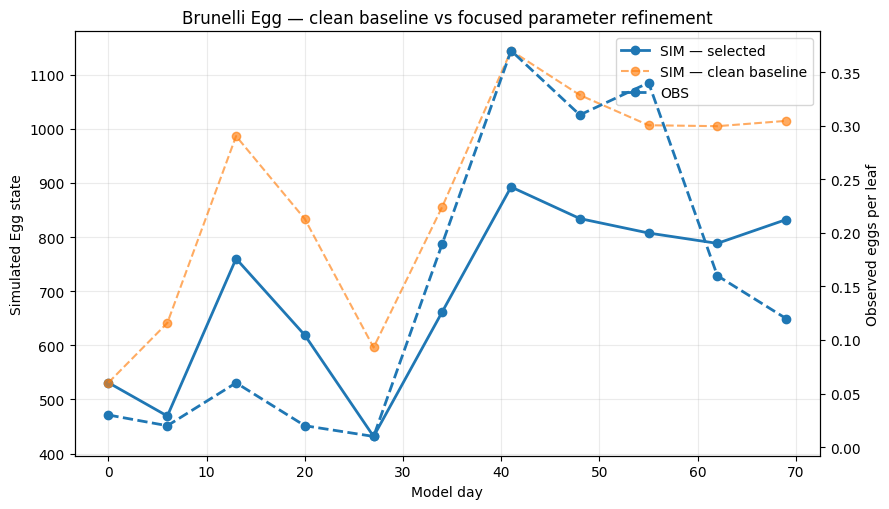

In [10]:
selected_sim_fast = BrunelliCoupledEngine(params=SELECTED_PARAMS, include_biomass=False).run()
selected_daily_fast = daily_rows(selected_sim_fast)
selected_egg_fast = selected_daily_fast.loc[EGG_LARVA_DAYS, "Eggs"].to_numpy(float)
selected_larva_fast = selected_daily_fast.loc[EGG_LARVA_DAYS, "Larvae"].to_numpy(float)
selected_adult_fast = adult_interval_exposure(selected_sim_fast)

comparison_metrics = pd.DataFrame([
    {"Run": "Clean baseline", "Stage": "Egg", **stage_metrics(egg_obs, baseline_egg)},
    {"Run": "Selected", "Stage": "Egg", **stage_metrics(egg_obs, selected_egg_fast)},
    {"Run": "Clean baseline", "Stage": "Larva", **stage_metrics(larva_obs, baseline_larva)},
    {"Run": "Selected", "Stage": "Larva", **stage_metrics(larva_obs, selected_larva_fast)},
    {"Run": "Clean baseline", "Stage": "Adult interval", **stage_metrics(adult_obs[1:], baseline_adult)},
    {"Run": "Selected", "Stage": "Adult interval", **stage_metrics(adult_obs[1:], selected_adult_fast)},
])
display(comparison_metrics)

fig, ax1 = plt.subplots(figsize=(9, 5.2))
ax1.plot(EGG_LARVA_DAYS, selected_egg_fast, marker="o", linewidth=2, label="SIM — selected")
ax1.plot(EGG_LARVA_DAYS, baseline_egg, marker="o", linewidth=1.5, linestyle="--", alpha=0.65, label="SIM — clean baseline")
ax1.set_xlabel("Model day")
ax1.set_ylabel("Simulated Egg state")
ax1.grid(alpha=0.25)
ax2 = ax1.twinx()
ax2.plot(EGG_LARVA_DAYS, egg_obs, marker="o", linestyle="--", linewidth=2, label="OBS")
ax2.set_ylabel("Observed eggs per leaf")
lines1, labels1 = ax1.get_legend_handles_labels(); lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")
ax1.set_title("Brunelli Egg — clean baseline vs focused parameter refinement")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Egg_baseline_vs_refined_OBS_SIM.png", dpi=220, bbox_inches="tight")
plt.show()


## 11. Final selected run with native TOMGRO biomass

The final selected parameter set is run with the native PyCrop `TOMGROBiomassModule`. A matched no-pest counterfactual uses the same forcing and crop initial conditions.


In [11]:
final_sim = BrunelliCoupledEngine(params=SELECTED_PARAMS, include_biomass=True, pest_on=True).run()
control_sim = BrunelliCoupledEngine(params=SELECTED_PARAMS, include_biomass=True, pest_on=False).run()
final_daily = daily_rows(final_sim)
control_daily = daily_rows(control_sim)

egg_pred = final_daily.loc[EGG_LARVA_DAYS, "Eggs"].to_numpy(float)
larva_pred = final_daily.loc[EGG_LARVA_DAYS, "Larvae"].to_numpy(float)
adult_pred = adult_interval_exposure(final_sim)

metrics_table = pd.DataFrame([
    {"Stage": "Egg", **stage_metrics(egg_obs, egg_pred)},
    {"Stage": "Larva", **stage_metrics(larva_obs, larva_pred)},
    {"Stage": "Adult interval", **stage_metrics(adult_obs[1:], adult_pred)},
])
display(metrics_table)
print("Final Larva peak day:", int(EGG_LARVA_DAYS[np.argmax(larva_pred)]))


,Stage,Pearson_r,Spearman_rho,Direction_match,Direction_total
0,Egg,0.783831,0.874718,8,10
1,Larva,0.777931,0.727273,8,10
2,Adult interval,0.738643,0.636364,7,9


Final Larva peak day: 41


## 12. Final raw OBS vs SIM figures


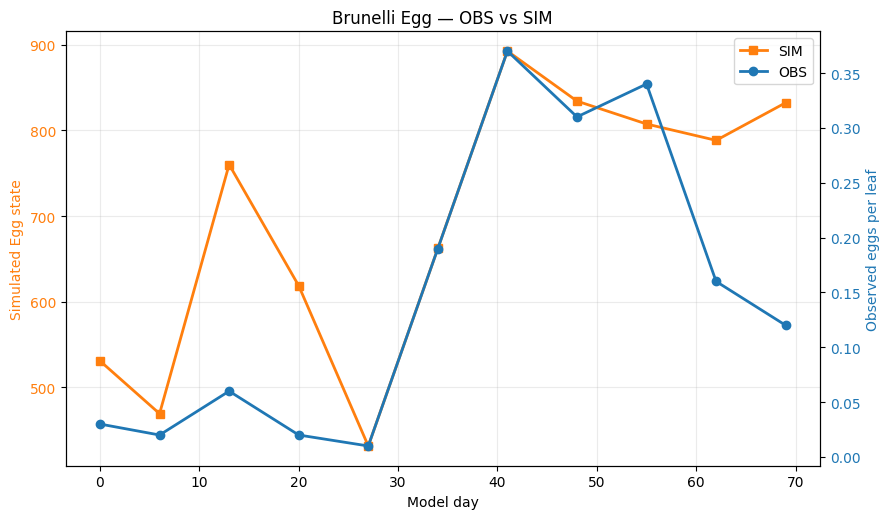

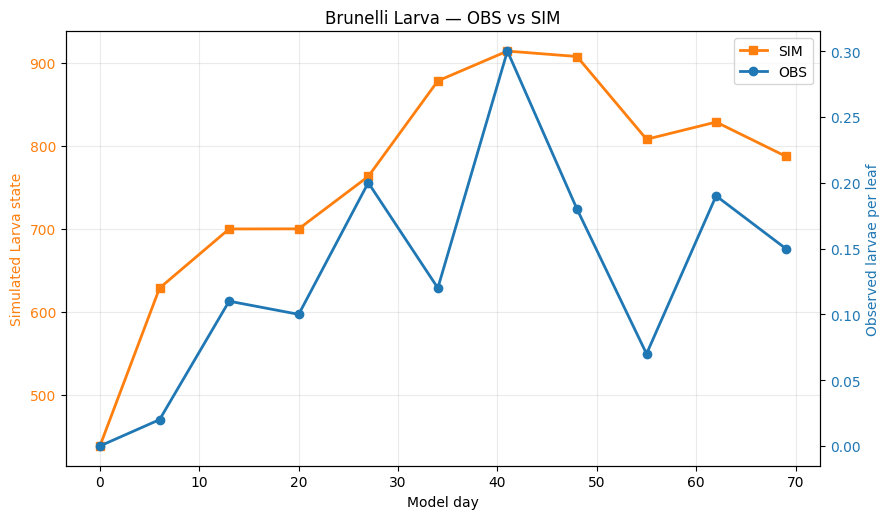

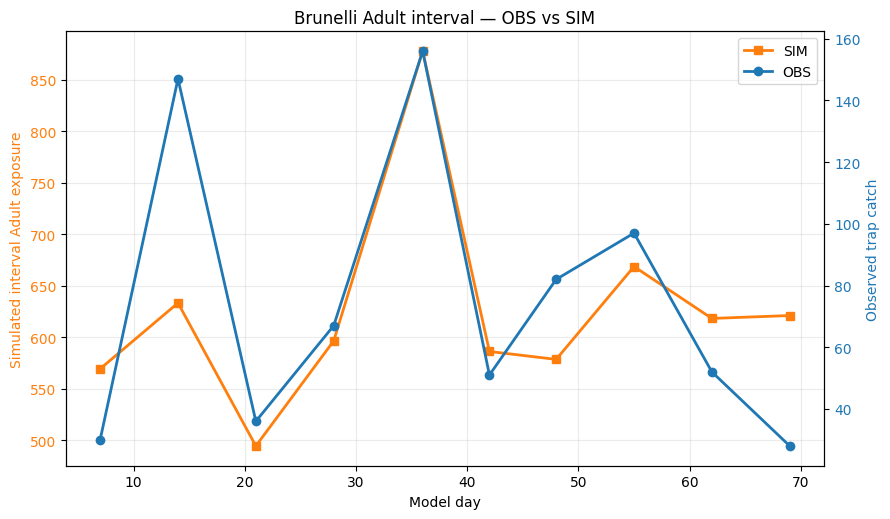

/mnt/data/milan_compare_update_v2/outputs_brunelli_common_SLA/Brunelli_Egg_OBS_SIM_FINAL.png
/mnt/data/milan_compare_update_v2/outputs_brunelli_common_SLA/Brunelli_Larva_OBS_SIM_FINAL.png
/mnt/data/milan_compare_update_v2/outputs_brunelli_common_SLA/Brunelli_Adult_OBS_SIM_FINAL.png


In [12]:
def obs_sim_plot(days, obs, sim, title, sim_ylabel, obs_ylabel, filename):
    fig, ax1 = plt.subplots(figsize=(9, 5.3))
    ax1.plot(days, sim, marker="s", linewidth=2, color="tab:orange", label="SIM")
    ax1.set_xlabel("Model day")
    ax1.set_ylabel(sim_ylabel, color="tab:orange")
    ax1.tick_params(axis="y", labelcolor="tab:orange")
    ax1.grid(alpha=0.25)
    ax2 = ax1.twinx()
    ax2.plot(days, obs, marker="o", linestyle="-", linewidth=2, color="tab:blue", label="OBS")
    ax2.set_ylabel(obs_ylabel, color="tab:blue")
    ax2.tick_params(axis="y", labelcolor="tab:blue")
    lines1, labels1 = ax1.get_legend_handles_labels(); lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")
    ax1.set_title(title)
    plt.tight_layout()
    path = OUTPUT_DIR / filename
    plt.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()
    return path

EGG_FIG = obs_sim_plot(EGG_LARVA_DAYS, egg_obs, egg_pred,
    "Brunelli Egg — OBS vs SIM", "Simulated Egg state", "Observed eggs per leaf", "Brunelli_Egg_OBS_SIM_FINAL.png")
LARVA_FIG = obs_sim_plot(EGG_LARVA_DAYS, larva_obs, larva_pred,
    "Brunelli Larva — OBS vs SIM", "Simulated Larva state", "Observed larvae per leaf", "Brunelli_Larva_OBS_SIM_FINAL.png")
ADULT_FIG = obs_sim_plot(ADULT_DAYS[1:], adult_obs[1:], adult_pred,
    "Brunelli Adult interval — OBS vs SIM", "Simulated interval Adult exposure", "Observed trap catch", "Brunelli_Adult_OBS_SIM_FINAL.png")

print(EGG_FIG)
print(LARVA_FIG)
print(ADULT_FIG)


## 13. Crop response and exports


In [13]:
daily_flow = final_sim.groupby("Day", as_index=False).agg(
    Hatching=("Hatching", lambda x: float(np.sum(x) / 24.0)),
    Larval_Inflow=("Larval_Inflow", lambda x: float(np.sum(x) / 24.0)),
    Pupation=("Pupation", lambda x: float(np.sum(x) / 24.0)),
    Damage_LAI=("Damage_LAI_Rate", lambda x: float(np.sum(x) / 24.0)),
)

daily_export = final_daily.copy()
daily_export["LAI_no_pest"] = control_daily["LAI"].to_numpy(float)
daily_export["Wf_no_pest"] = control_daily["Wf"].to_numpy(float)
daily_export["W_no_pest"] = control_daily["W"].to_numpy(float)
daily_export["Wm_no_pest"] = control_daily["Wm"].to_numpy(float)
daily_export["LAI_Loss_vs_NoPest"] = daily_export["LAI_no_pest"] - daily_export["LAI"]
daily_export["Fruit_Biomass_Loss_vs_NoPest"] = daily_export["Wf_no_pest"] - daily_export["Wf"]
daily_export = daily_export.merge(daily_flow, on="Day", how="left")
daily_export["Cumulative_Damage_LAI"] = daily_export["Damage_LAI"].cumsum()

config_df = pd.DataFrame([
    {"Parameter": "E0", "Value": PEST_IC["E0"]},
    {"Parameter": "L0", "Value": PEST_IC["L0"]},
    {"Parameter": "P0", "Value": PEST_IC["P0"]},
    {"Parameter": "A0", "Value": PEST_IC["A0"]},
    {"Parameter": "IC_search_method", "Value": "Differential Evolution"},
    {"Parameter": "IC_search_seed", "Value": 42},
    {"Parameter": "Damage_interface", "Value": "SLA-based Brunelli"},
    {"Parameter": "SLA", "Value": COMMON_DAMAGE["SLA"]},
    {"Parameter": "Pest_resource_conversion", "Value": "F_resource = LAI / Omega"},
    {"Parameter": "IC_search_rerun_in_this_execution", "Value": bool(RUN_DE_IC_SEARCH)},
    {"Parameter": "Focused_search_rerun_in_this_execution", "Value": bool(RUN_FOCUSED_SEARCH)},
    *[{"Parameter": k, "Value": v} for k, v in SELECTED_PARAMS.items()],
])

config_df.to_csv(OUTPUT_DIR / "final_configuration.csv", index=False)
metrics_table.to_csv(OUTPUT_DIR / "pattern_metrics.csv", index=False)
daily_export.to_csv(OUTPUT_DIR / "brunelli_final_daily_states_and_crop_impact.csv", index=False)
daily_flow.to_csv(OUTPUT_DIR / "daily_flow_diagnostics.csv", index=False)
comparison_metrics.to_csv(OUTPUT_DIR / "baseline_vs_selected_metrics.csv", index=False)

summary = pd.DataFrame({
    "Quantity": [
        "Egg direction matches",
        "Larva direction matches",
        "Larva survey peak day",
        "Adult interval direction matches",
        "Final LAI with pest",
        "Final LAI without pest",
        "Final Wf with pest",
        "Final Wf without pest",
    ],
    "Value": [
        f"{direction_count(egg_obs, egg_pred)}/10",
        f"{direction_count(larva_obs, larva_pred)}/10",
        int(EGG_LARVA_DAYS[np.argmax(larva_pred)]),
        f"{direction_count(adult_obs[1:], adult_pred)}/9",
        float(final_daily["LAI"].iloc[-1]),
        float(control_daily["LAI"].iloc[-1]),
        float(final_daily["Wf"].iloc[-1]),
        float(control_daily["Wf"].iloc[-1]),
    ],
})
display(summary)
summary.to_csv(OUTPUT_DIR / "final_numerical_summary.csv", index=False)


,Quantity,Value
0,Egg direction matches,8/10
1,Larva direction matches,8/10
2,Larva survey peak day,41
3,Adult interval direction matches,7/9
4,Final LAI with pest,1.093284
5,Final LAI without pest,1.474156
6,Final Wf with pest,489.872674
7,Final Wf without pest,561.148145


## 14. Provenance summary

- Base life-cycle equations and resource-consumer formulation: Milan/Coppola / Bevacqua, Coppola & Casagrandi.
- Larval thermal response: Sharpe–DeMichele formulation using the published Mohamed et al. coefficients.
- Initial pest state: Differential Evolution over `(E0,L0,P0,A0)` with the objective, bounds, and optimizer settings documented in Section 7 of this notebook. The retained rounded solution is `(531,438,349,0)` and is loaded by default for fast reruns.
- The IC-search stage holds `DE_IC_RATE_PARAMS` fixed; after the ICs are frozen, the focused rate refinement varies only `a2`, `b2`, `mu_E`, and `nu`.
- No high-temperature Egg penalty, heat memory, fixed heat lag, separate Egg-duration multiplier, immigration term, observation scaling, or smoothing is retained in the final workflow.
- Adult observations are evaluated through interval exposure rather than as instantaneous population measurements.


## 15. Final crop-impact figures with the SLA-based Brunelli damage interface

These figures show the with-pest trajectory against the matched no-pest TOMGRO counterfactual. Fruit biomass is affected **indirectly** through the reduced canopy; there is no direct fruit-feeding term.

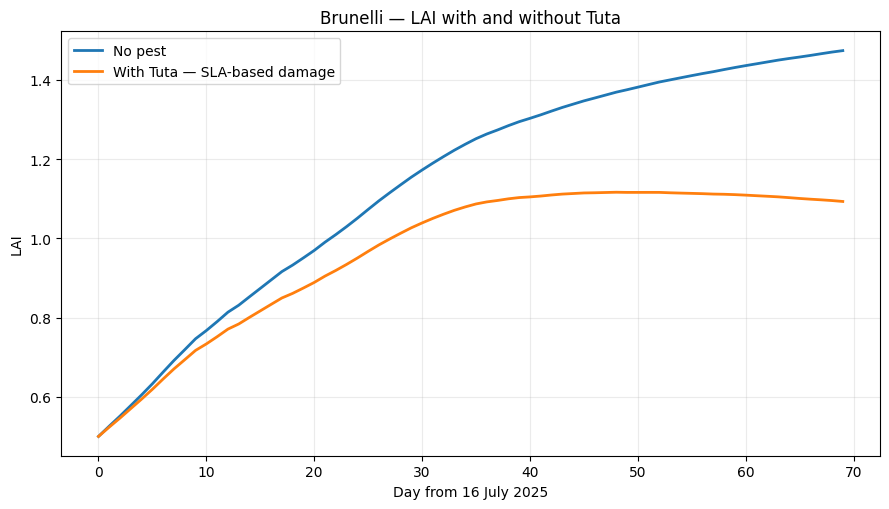

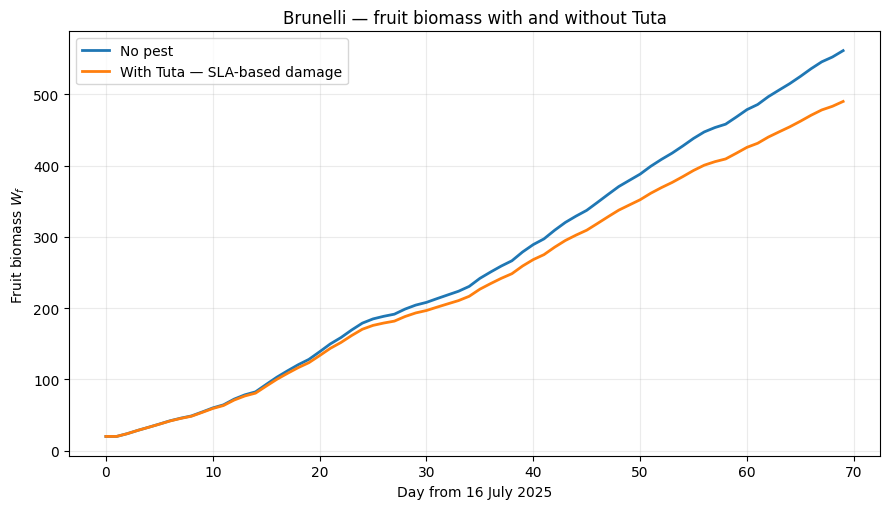

,Day,LAI_with_pest,LAI_no_pest,LAI_loss_pct,Wf_with_pest,Wf_no_pest,Wf_loss_pct
0,69,1.0933,1.4742,25.8366,489.8727,561.1481,12.7017


In [14]:
# Final LAI and fruit-biomass figures
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(control_daily["Day"], control_daily["LAI"], linewidth=2, label="No pest")
ax.plot(final_daily["Day"], final_daily["LAI"], linewidth=2, label="With Tuta — SLA-based damage")
ax.set_xlabel("Day from 16 July 2025")
ax.set_ylabel("LAI")
ax.set_title("Brunelli — LAI with and without Tuta")
ax.grid(alpha=0.25); ax.legend(); fig.tight_layout()
LAI_FIG = OUTPUT_DIR / "Brunelli_LAI_with_without_Tuta_COMMON_SLA.png"
fig.savefig(LAI_FIG, dpi=220, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(control_daily["Day"], control_daily["Wf"], linewidth=2, label="No pest")
ax.plot(final_daily["Day"], final_daily["Wf"], linewidth=2, label="With Tuta — SLA-based damage")
ax.set_xlabel("Day from 16 July 2025")
ax.set_ylabel("Fruit biomass $W_f$")
ax.set_title("Brunelli — fruit biomass with and without Tuta")
ax.grid(alpha=0.25); ax.legend(); fig.tight_layout()
WF_FIG = OUTPUT_DIR / "Brunelli_Wf_with_without_Tuta_COMMON_SLA.png"
fig.savefig(WF_FIG, dpi=220, bbox_inches="tight")
plt.show()

# Relative crop impact on the common Day-69 horizon
r69 = final_daily.loc[69]
n69 = control_daily.loc[69]
impact69 = pd.DataFrame([{
    "Day": 69,
    "LAI_with_pest": float(r69["LAI"]),
    "LAI_no_pest": float(n69["LAI"]),
    "LAI_loss_pct": float(100*(n69["LAI"]-r69["LAI"])/n69["LAI"]),
    "Wf_with_pest": float(r69["Wf"]),
    "Wf_no_pest": float(n69["Wf"]),
    "Wf_loss_pct": float(100*(n69["Wf"]-r69["Wf"])/n69["Wf"]),
}])
display(impact69.round(4))
impact69.to_csv(OUTPUT_DIR / "crop_impact_day69_common_SLA.csv", index=False)


## 16. Final audit checks

The final cell verifies that the executed notebook is internally consistent and that the final formulation preserves the intended Brunelli timing.

In [15]:
# Hard final audit
assert COMMON_DAMAGE["SLA"] == 0.018
assert PEST_IC == {"E0": 531.0, "L0": 438.0, "P0": 349.0, "A0": 0.0}
assert int(EGG_LARVA_DAYS[np.argmax(egg_pred)]) == 41
assert int(EGG_LARVA_DAYS[np.argmax(larva_pred)]) == 41
assert int(ADULT_DAYS[1:][np.argmax(adult_pred)]) == 36
assert direction_count(egg_obs, egg_pred) >= 8
assert direction_count(larva_obs, larva_pred) >= 8
assert direction_count(adult_obs[1:], adult_pred) >= 7
assert float(impact69.loc[0, "LAI_loss_pct"]) > 0
assert float(impact69.loc[0, "Wf_loss_pct"]) > 0
for p in [EGG_FIG, LARVA_FIG, ADULT_FIG, LAI_FIG, WF_FIG]:
    assert Path(p).exists(), p
print("FINAL BRUNELLI SLA-BASED AUDIT PASSED")
print("Selected parameters:", SELECTED_PARAMS)
print("Initial pest state:", PEST_IC)
print("Peak days: Egg=41, Larva=41, Adult interval=36")


FINAL BRUNELLI SLA-BASED AUDIT PASSED
Selected parameters: {'a2': 48.0, 'b2': 0.11, 'mu_E': 0.32, 'nu': 0.000745}
Initial pest state: {'E0': 531.0, 'L0': 438.0, 'P0': 349.0, 'A0': 0.0}
Peak days: Egg=41, Larva=41, Adult interval=36
